<a href="https://colab.research.google.com/github/wujh03/MSSP6070/blob/main/WeeklyModules/Week08/week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!git clone https://github.com/wujh03/MSSP6070.git

fatal: destination path 'MSSP6070' already exists and is not an empty directory.


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv(
    '/content/MSSP6070/data/InternetSales.csv',
    encoding='latin1'
)

print(df.shape)
print(df.columns.tolist())
df.head()


(60398, 60)
['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'CustomerPONumber', 'OrderDate', 'DueDat

/tmp/ipykernel_1457/2339743427.py:5: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [8]:
# Convert OrderDate to datetime
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# Extract the year
df['Year'] = df['OrderDate'].dt.year

# Calculate yearly sales
yearly_sales = df.groupby('Year')['SalesAmount'].sum()

print(yearly_sales)


Year
2010    4.342104e+04
2011    7.075526e+06
2012    5.842485e+06
2013    1.635155e+07
2014    4.569472e+04
Name: SalesAmount, dtype: float64


2014: $19,032,544.90
2015: $23,670,557.10
2016: $28,308,569.31
2017: $32,946,581.52
2018: $37,584,593.72


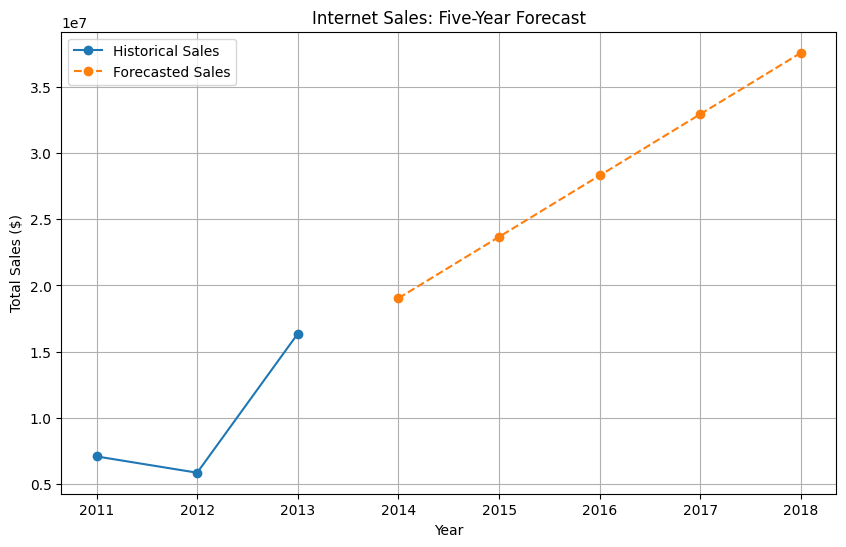

In [9]:

from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# 1. Use only complete years
sales = yearly_sales.loc[2011:2013]

# 2. Prepare data for linear regression
X = sales.index.values.reshape(-1, 1)
y = sales.values

# 3. Train the model
model = LinearRegression()
model.fit(X, y)

# 4. Predict the next five years
future_years = np.arange(2014, 2019)
predictions = model.predict(future_years.reshape(-1, 1))

# 5. Display forecast
for year, amount in zip(future_years, predictions):
    print(f"{year}: ${amount:,.2f}")

# 6. Plot sales trend and forecast
plt.figure(figsize=(10, 6))

plt.plot(sales.index, sales.values,
         marker='o', label='Historical Sales')

plt.plot(future_years, predictions,
         marker='o', linestyle='--',
         label='Forecasted Sales')

plt.title('Internet Sales: Five-Year Forecast')
plt.xlabel('Year')
plt.ylabel('Total Sales ($)')
plt.legend()
plt.grid(True)
plt.show()


In [10]:
# Calculate total sales for each product
product_sales = df.groupby('EnglishProductName')['SalesAmount'].sum()

# Sort by highest sales
product_sales = product_sales.sort_values(ascending=False)

# Show top 10 products
print(product_sales.head(10))

# Find the product with the highest sales
print("\nTop-selling product:", product_sales.index[0])
print(f"Total sales: ${product_sales.iloc[0]:,.2f}")


EnglishProductName
Mountain-200 Black, 46     1.373470e+06
Mountain-200 Black, 42     1.363142e+06
Mountain-200 Silver, 38    1.339463e+06
Mountain-200 Silver, 46    1.301100e+06
Mountain-200 Black, 38     1.294866e+06
Mountain-200 Silver, 42    1.257435e+06
Road-150 Red, 48           1.205877e+06
Road-150 Red, 62           1.202299e+06
Road-150 Red, 52           1.080638e+06
Road-150 Red, 56           1.055590e+06
Name: SalesAmount, dtype: float64

Top-selling product: Mountain-200 Black, 46
Total sales: $1,373,469.55


Based on the summary statistics, **Mountain-200 Black, 46** generated the highest total sales, approximately $1.37 million, among all products in the dataset.

The five-year linear regression forecast indicates an increasing sales trend from 2014 to 2018. However, because the model uses only three complete years of historical sales data (2011–2013), the forecast should be interpreted with caution.